In [1]:
%pylab inline
import galsim
import lsst.afw.image as afwImg

Populating the interactive namespace from numpy and matplotlib


# The shape of correlation function

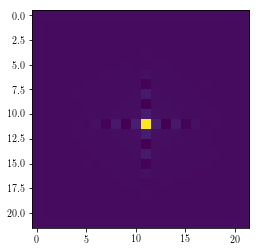

In [2]:
rng = galsim.BaseDeviate(0)
scale=0.168
variance=0.2
ngrid=2048
corFname='./wrkDir/s19/s19-pre/corPre/corGroup-01.fits'
corNoise    =   galsim.getCOSMOSNoise(file_name=corFname,rng=rng,cosmos_scale=scale,variance=variance)
corArray=corNoise.drawImage(scale=scale).array
plt.imshow(corArray)

0.010636136366490974
0.010465067
the estimated variance is: 0.20


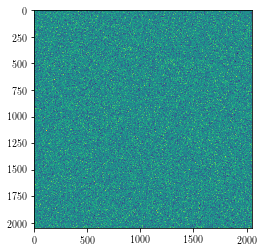

In [3]:
gal_image   =   galsim.ImageF(ngrid,ngrid,scale=scale)
corNoise.applyTo(gal_image)
gal_array=gal_image.array
plt.imshow(gal_array)
var=np.var(gal_array)
cov1=0.
for i in range(2000):
    cov1+=np.average(gal_array[:,i]*gal_array[:,i+1])
print(cov1/2000)
print(corArray[11,12])
print('the estimated variance is: %.2f' %var)

(21, 21)


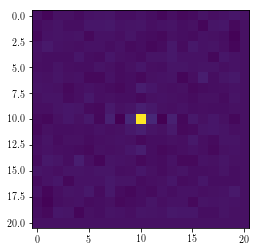

In [4]:
corFname    =   './wrkDir/s19/s19-pre/corPre/corTract-10283.fits'
a=pyfits.getdata(corFname)
print(a.shape)
plt.imshow(a)

# The variance after simulation

In [5]:
expData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-00000.fits',ext=1)
mskData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-00000.fits',ext=2)

0.00439111
0.43530083


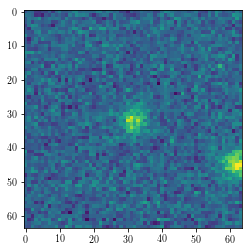

In [6]:
iplot=1
jplot=0
expShow=expData[jplot*64:(jplot+1)*64,iplot*64:(iplot+1)*64]
print(np.var(expShow))
print(np.max(expShow))
plt.imshow(expShow)

In [7]:
help(plt.imshow)

Help on function imshow in module matplotlib.pyplot:

imshow(X, cmap=None, norm=None, aspect=None, interpolation=None, alpha=None, vmin=None, vmax=None, origin=None, extent=None, shape=None, filternorm=1, filterrad=4.0, imlim=None, resample=None, url=None, *, data=None, **kwargs)
    Display an image, i.e. data on a 2D regular raster.
    
    Parameters
    ----------
    X : array-like or PIL image
        The image data. Supported array shapes are:
    
        - (M, N): an image with scalar data. The data is visualized
          using a colormap.
        - (M, N, 3): an image with RGB values (float or uint8).
        - (M, N, 4): an image with RGBA values (float or uint8), i.e.
          including transparency.
    
        The first two dimensions (M, N) define the rows and columns of
        the image.
    
        The RGB(A) values should be in the range [0 .. 1] for floats or
        [0 .. 255] for integers.  Out-of-range values will be clipped to
        these bounds.
    
   

In [ ]:
cmap

In [17]:
varMeas=[]
ntest=10
for i in range(ntest):
    expData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-%05d.fits' %i,ext=1)
    mskData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-%05d.fits' %i,ext=2)
    var=np.var(expData[mskData==0])
    varMeas.append(var)
    print(var)

0.003265223
0.0027445653
0.0038408248
0.0026147272
0.0034167762
0.0020136775
0.0043352316
0.0033892517
0.0028583496
0.0028855233


In [18]:
import astropy.io.ascii as ascii
varMeas=np.array(varMeas)
info=ascii.read('wrkDir/s19/s19-pre/info.csv')[0:ntest]
varinput=info['var']
np.average(varMeas/varinput)

0.9462479339629633